<a href="https://colab.research.google.com/github/CalogeroGabriele/Artificial-Intelligence/blob/main/Supervised-Learning/Polynomial_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [34]:
import matplotlib.pyplot as plt
import numpy as np

In [35]:
m = 200 #examples
n = 1 #features

X = 2 * np.random.rand(m,n)

# Y = f(x)
theta = 5
real_Y = 2 + theta * X + theta * np.square(X)

# Y = f(x) + Error
Y = 2 + theta * X + theta * np.square(X) + 0.7 * np.random.randn(m,1)

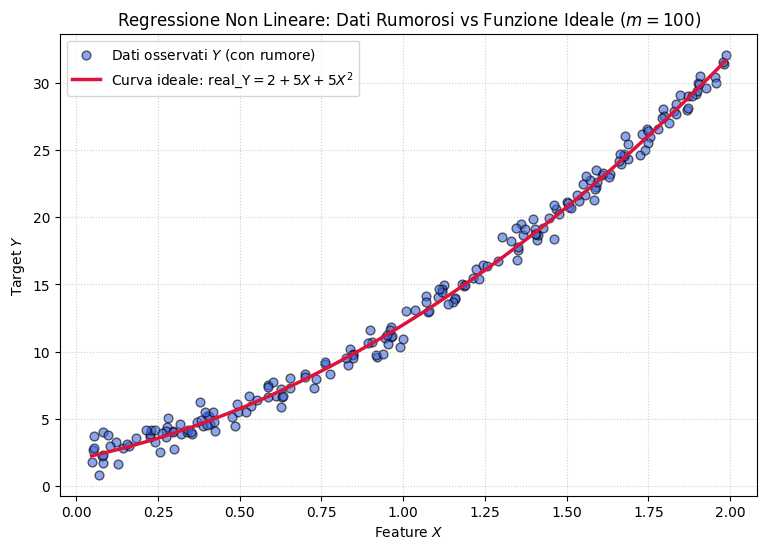

In [41]:
# 2. Ordinamento per il tracciamento della curva continua
# Ordiniamo X e calcoliamo i rispettivi indici ordinati
sort_idx = np.argsort(X[:, 0])
X_sorted = X[sort_idx]
real_Y_sorted = real_Y[sort_idx]

# 3. Creazione del grafico
plt.figure(figsize=(9, 6))

# Punti rumorosi Y nello scatter plot
plt.scatter(
    X,
    Y,
    color="royalblue",
    alpha=0.6,
    edgecolor="k",
    s=40,
    label="Dati osservati $Y$ (con rumore)",
)

# Curva ideale f(x) continua
plt.plot(
    X_sorted,
    real_Y_sorted,
    color="crimson",
    linewidth=2.5,
    label=r"Curva ideale: $\text{real\_Y} = 2 + 5X + 5X^2$",
)

# Etichette, griglia e legenda
plt.xlabel("Feature $X$")
plt.ylabel("Target $Y$")
plt.title(
    "Regressione Non Lineare: Dati Rumorosi vs Funzione Ideale ($m=100$)"
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.show()

In [37]:
X_b = np.c_[np.ones((m, 1)), X, np.square(X)]
print(f"Shape di X_b: {X_b.shape}\n")

# Bias , theta1, theta2
initial_thetas = np.array([[0],[0],[0]])
print(f"Shape di initial_thetas: {initial_thetas.shape}\n")

def MSE(X, theta, Y):
  errors = (X_b @ theta) - Y

  return ((errors.T @ errors) / len(X_b)).item()

MSE(X_b, initial_thetas, Y)


Shape di X_b: (200, 3)

Shape di initial_thetas: (3, 1)



281.6294455124256

In [38]:
#Equazione normale per il calcolo di theta*
final_theta = np.linalg.inv(X_b.T @ X_b) @ X_b.T @ Y
print(final_theta)

[[2.14287744]
 [4.82049721]
 [5.08006455]]


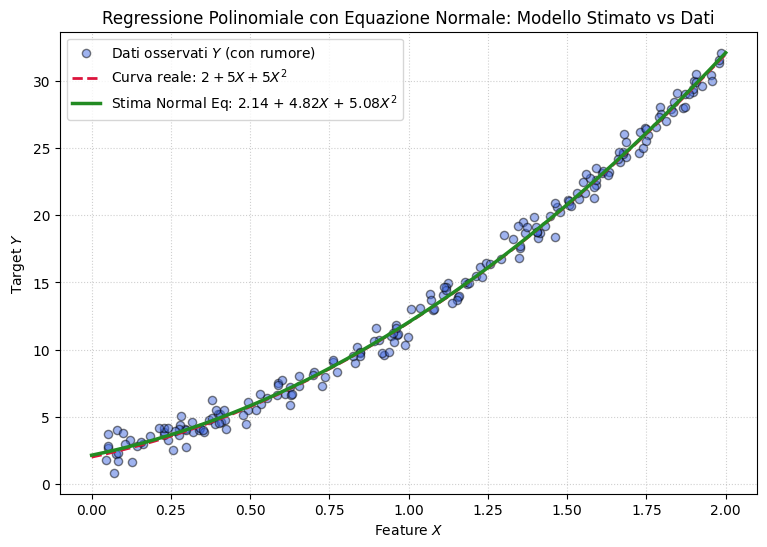

In [40]:
# 4. Generazione di una griglia regolare densa su X per un tracciamento liscio
x_dense = np.linspace(0, 2, 200).reshape(-1, 1)

# Matrice delle feature per i punti della griglia
x_dense_b = np.c_[np.ones((len(x_dense), 1)), x_dense, np.square(x_dense)]

# Predizione del modello stimato: Y_pred = x_dense_b @ final_theta
y_pred_dense = x_dense_b @ final_theta

# Curva reale ideale di riferimento
y_real_dense = 2 + theta * x_dense + theta * np.square(x_dense)

# 5. Creazione del grafico 2D
plt.figure(figsize=(9, 6))

# Punti campionati con rumore
plt.scatter(
    X,
    Y,
    color="royalblue",
    alpha=0.5,
    edgecolor="k",
    s=35,
    label="Dati osservati $Y$ (con rumore)",
)

# Curva ideale teorica f(x)
plt.plot(
    x_dense,
    y_real_dense,
    color="crimson",
    linewidth=2,
    linestyle="--",
    label=r"Curva reale: $2 + 5X + 5X^2$",
)

# Curva stimata tramite l'Equazione Normale
plt.plot(
    x_dense,
    y_pred_dense,
    color="forestgreen",
    linewidth=2.5,
    label=(
        f"Stima Normal Eq: {final_theta[0, 0]:.2f} + "
        f"{final_theta[1, 0]:.2f}$X$ + {final_theta[2, 0]:.2f}$X^2$"
    ),
)

# Etichette, griglia e legenda
plt.xlabel("Feature $X$")
plt.ylabel("Target $Y$")
plt.title(
    "Regressione Polinomiale con Equazione Normale: Modello Stimato vs Dati"
)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend()

plt.show()